<a href="https://colab.research.google.com/github/AnjanaVP231/ML/blob/main/lab7_LDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 10 records:
   Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6    Class
0   2.665675   1.019702   0.474698  -3.723351  -1.686231   2.455737  Class_A
1   2.205112  -4.060952   2.157308   2.261413   0.479444   3.549782  Class_B
2   0.951933   1.490185  -1.024187  -2.090485  -0.468948  -0.674708  Class_C
3   4.805042   2.695314  -1.484898  -3.500672  -2.296602   1.343669  Class_A
4  -1.154440   0.405701   0.817766   0.705357   3.607272   1.352961  Class_A
5   3.419831   1.993340   0.529693  -3.084467  -0.886804   1.265844  Class_A
6   0.203571  -1.385217   0.586364   2.462011   2.412413  -0.983078  Class_B
7   1.263865  -3.293013   0.307407   3.185462   2.718337   0.297723  Class_B
8   1.991466  -3.079682   0.057013  -0.653363   2.955657   1.327113  Class_B
9   1.721758  -1.000312  -0.193659  -2.101795  -2.584006   1.519436  Class_C

Dataset shape: (240, 7)

Column names: ['Feature_1', 'Feature_2', 'Feature_3', 'Feature_4', 'Feature_5', 'Feature_6', 'Class']

Descri

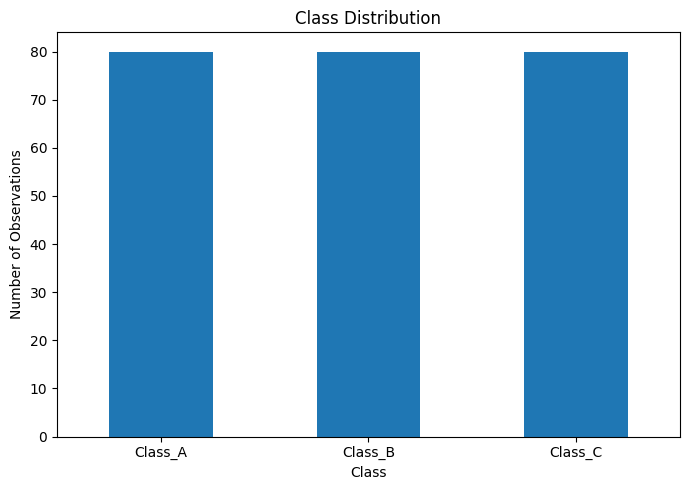

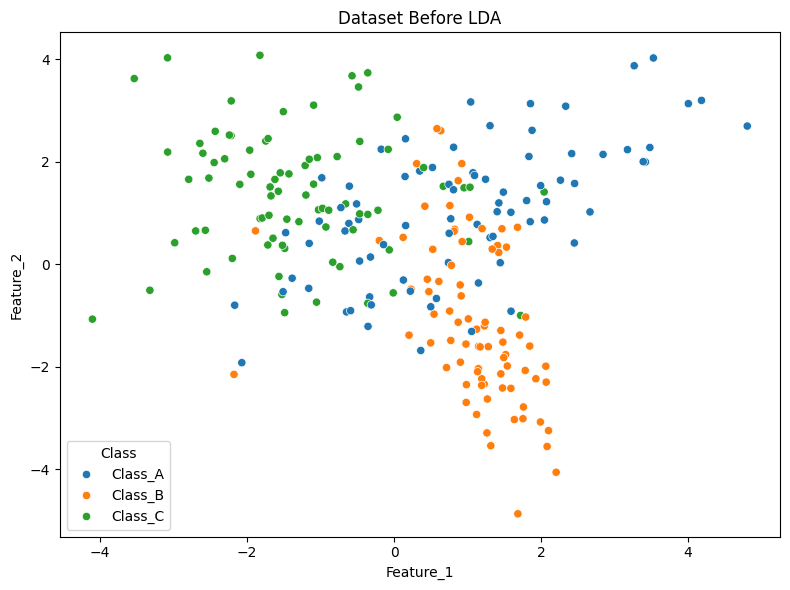


Original training shape: (168, 6)
Original testing shape: (72, 6)
LDA training shape: (168, 2)
LDA testing shape: (72, 2)

Number of classes: 3
Maximum possible LDA components: 2


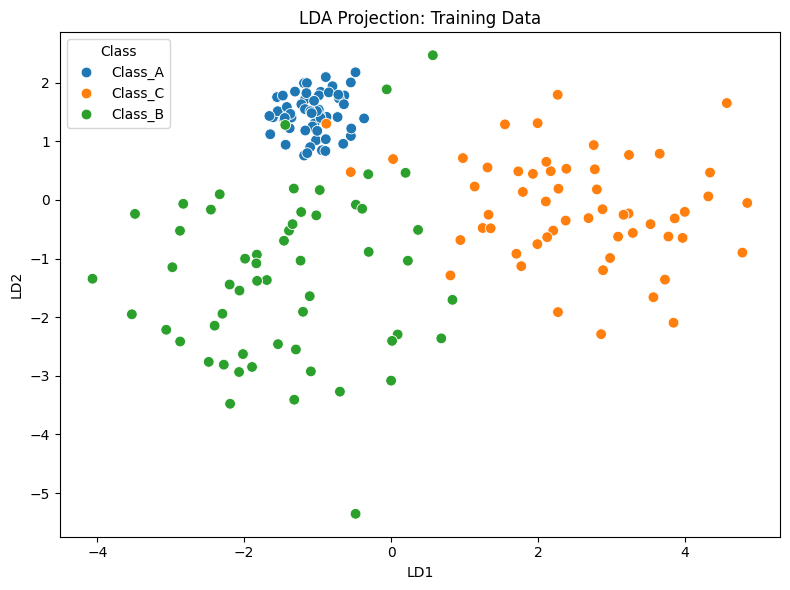


LDA explained discriminant variance ratios:
[0.70480905 0.29519095]
Sum of ratios: 1.0

Classification Performance:
              Model  Accuracy  Macro Precision  Macro Recall  Macro F1-score
Original 6 Features    0.9167            0.925        0.9167          0.9152
   LDA 2 Components    0.9167            0.925        0.9167          0.9152


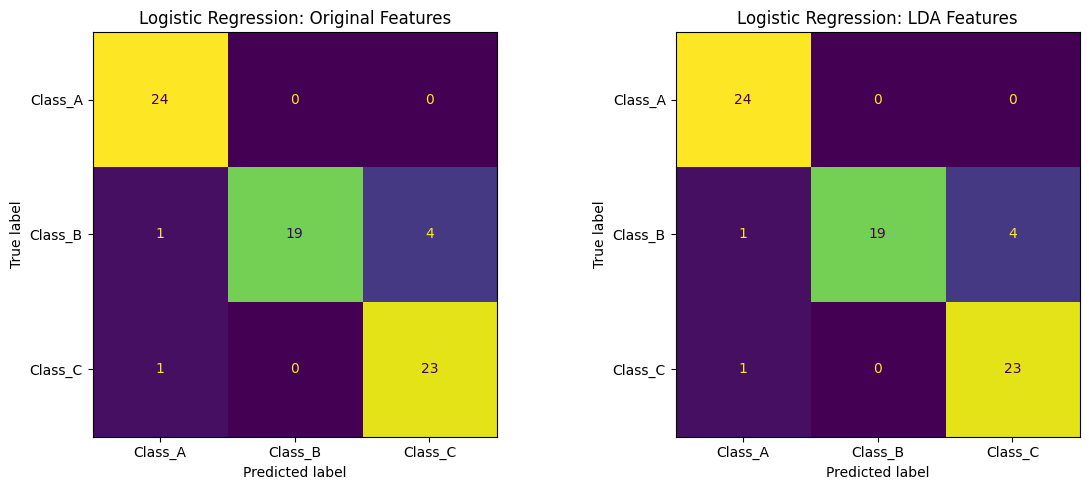


Performance: One vs Two LDA Components
             Model  Accuracy  Macro Precision  Macro Recall  Macro F1-score
LDA 1 Component(s)    0.6806           0.6673        0.6806          0.6714
LDA 2 Component(s)    0.9167           0.9250        0.9167          0.9152


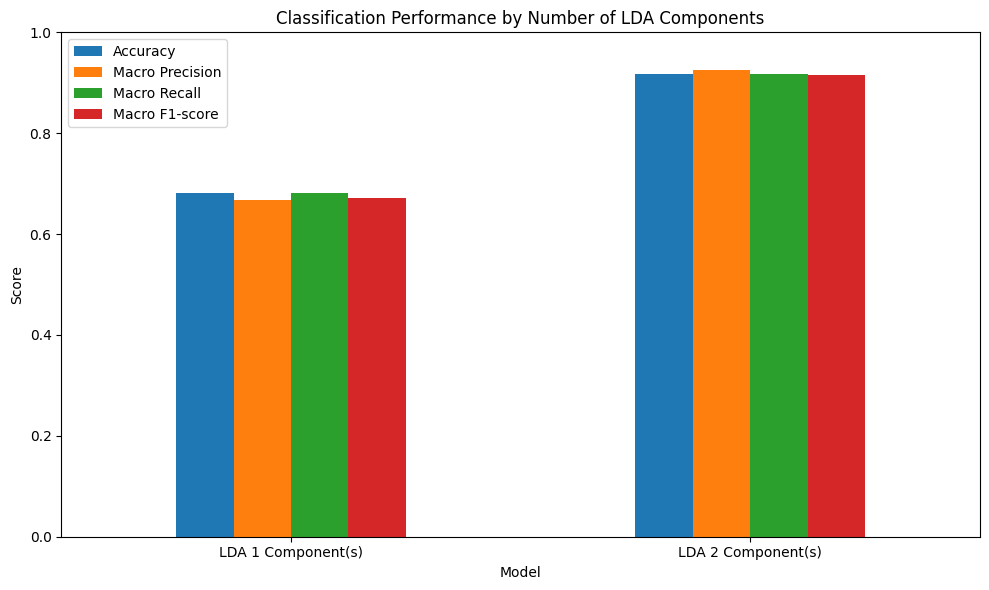

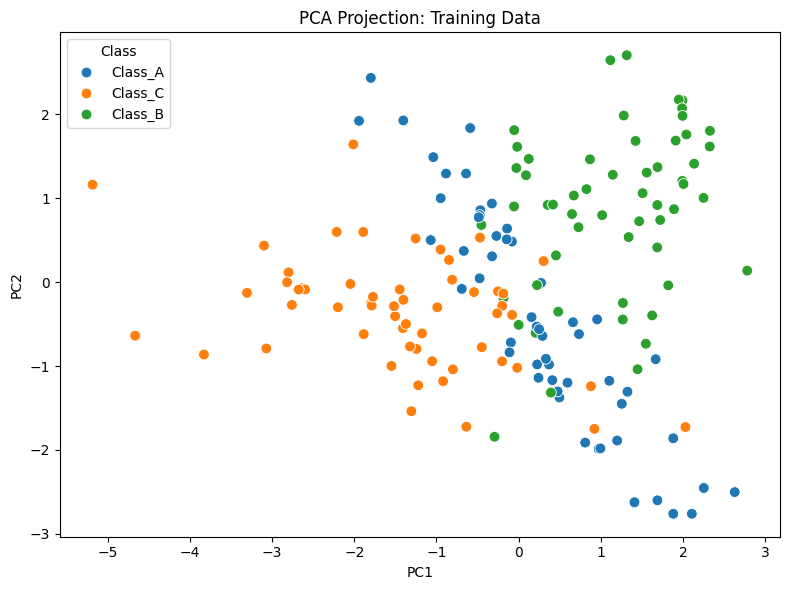


PCA explained variance ratios:
[0.37788802 0.23996096]
Sum of PCA variance ratios: 0.6178489799306565

LDA explained discriminant variance ratios:
[0.70480905 0.29519095]
Sum of LDA ratios: 1.0

Within-class scatter matrix (S_W):
[[ 88.1826  13.0822  13.8446 -19.9344 -77.0532  34.4133]
 [ 13.0822 101.1807   0.4246  -4.8915 -13.8596 -17.0303]
 [ 13.8446   0.4246 165.5721  -6.5874 -14.1749   4.158 ]
 [-19.9344  -4.8915  -6.5874 105.2019  34.7937   8.8624]
 [-77.0532 -13.8596 -14.1749  34.7937 167.2982 -76.7852]
 [ 34.4133 -17.0303   4.158    8.8624 -76.7852  84.3549]]

Between-class scatter matrix (S_B):
[[ 79.8174 -51.8196  -6.9923  39.8952  -4.4144  80.9755]
 [-51.8196  66.8193  -3.221  -63.6086   6.7626 -45.5297]
 [ -6.9923  -3.221    2.4279   5.3255  -0.5248  -8.741 ]
 [ 39.8952 -63.6086   5.3255  62.7981  -6.6352  32.4705]
 [ -4.4144   6.7626  -0.5248  -6.6352   0.7018  -3.6514]
 [ 80.9755 -45.5297  -8.741   32.4705  -3.6514  83.6451]]

LDA objective:
J(w) = (w.T @ S_B @ w) / (w.T 

In [ ]:

# ============================================================
# LDA LAB: Linear Discriminant Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. LOAD AND UNDERSTAND THE DATASET
# ------------------------------------------------------------

df = pd.read_csv("/content/LDA_Dataset.csv")
df.columns = df.columns.str.strip()

print("First 10 records:")
print(df.head(10))

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

print("\nDescriptive statistics:")
print(df.describe())

print("\nMissing-value counts:")
print(df.isnull().sum())

feature_cols = [
    "Feature_1", "Feature_2", "Feature_3",
    "Feature_4", "Feature_5", "Feature_6"
]

if not all(col in df.columns for col in feature_cols + ["Class"]):
    raise ValueError(
        "Dataset must contain Feature_1 to Feature_6 and Class."
    )

if df[feature_cols + ["Class"]].isnull().any().any():
    raise ValueError("Missing values found. Please clean the dataset.")

X = df[feature_cols]
y = df["Class"]

print("\nInput features:", feature_cols)
print("Target label: Class")

print("\nClass distribution:")
print(y.value_counts())

y.value_counts().plot(kind="bar", figsize=(7, 5))
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Scatter plot before LDA
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="Feature_1",
    y="Feature_2",
    hue="Class"
)
plt.title("Dataset Before LDA")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. PREPARE DATA AND APPLY LDA
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lda = LinearDiscriminantAnalysis(n_components=2)

X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

print("\nOriginal training shape:", X_train_scaled.shape)
print("Original testing shape:", X_test_scaled.shape)
print("LDA training shape:", X_train_lda.shape)
print("LDA testing shape:", X_test_lda.shape)

print("\nNumber of classes:", y.nunique())
print("Maximum possible LDA components:",
      min(X.shape[1], y.nunique() - 1))

# ------------------------------------------------------------
# 3. VISUALIZE AND INTERPRET LDA COMPONENTS
# ------------------------------------------------------------

lda_plot = pd.DataFrame({
    "LD1": X_train_lda[:, 0],
    "LD2": X_train_lda[:, 1],
    "Class": y_train.to_numpy()
})

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=lda_plot,
    x="LD1",
    y="LD2",
    hue="Class",
    s=60
)
plt.title("LDA Projection: Training Data")
plt.tight_layout()
plt.show()

print("\nLDA explained discriminant variance ratios:")
print(lda.explained_variance_ratio_)
print("Sum of ratios:", lda.explained_variance_ratio_.sum())

# ------------------------------------------------------------
# COMMON FUNCTION FOR CLASSIFICATION EVALUATION
# ------------------------------------------------------------

def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }


# ------------------------------------------------------------
# 4. CLASSIFICATION BEFORE AND AFTER LDA
# ------------------------------------------------------------

# Logistic Regression using all six original features
lr_original = LogisticRegression(max_iter=1000, random_state=42)
lr_original.fit(X_train_scaled, y_train)

pred_original = lr_original.predict(X_test_scaled)

# Logistic Regression using two LDA components
lr_lda = LogisticRegression(max_iter=1000, random_state=42)
lr_lda.fit(X_train_lda, y_train)

pred_lda = lr_lda.predict(X_test_lda)

results = [
    evaluate_model("Original 6 Features", y_test, pred_original),
    evaluate_model("LDA 2 Components", y_test, pred_lda)
]

results_df = pd.DataFrame(results)

print("\nClassification Performance:")
print(results_df.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_original,
    ax=axes[0], colorbar=False
)
axes[0].set_title("Logistic Regression: Original Features")

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_lda,
    ax=axes[1], colorbar=False
)
axes[1].set_title("Logistic Regression: LDA Features")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. STUDY THE NUMBER OF LDA COMPONENTS
# ------------------------------------------------------------

component_results = []

for n_components in [1, 2]:
    lda_model = LinearDiscriminantAnalysis(
        n_components=n_components
    )

    X_train_reduced = lda_model.fit_transform(
        X_train_scaled, y_train
    )
    X_test_reduced = lda_model.transform(X_test_scaled)

    classifier = LogisticRegression(
        max_iter=1000,
        random_state=42
    )
    classifier.fit(X_train_reduced, y_train)

    predictions = classifier.predict(X_test_reduced)

    component_results.append(
        evaluate_model(
            f"LDA {n_components} Component(s)",
            y_test,
            predictions
        )
    )

component_df = pd.DataFrame(component_results)

print("\nPerformance: One vs Two LDA Components")
print(component_df.round(4).to_string(index=False))

component_df.set_index("Model")[
    ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Classification Performance by Number of LDA Components")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. COMPARE LDA WITH PCA
# ------------------------------------------------------------

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)

pca_plot = pd.DataFrame({
    "PC1": X_train_pca[:, 0],
    "PC2": X_train_pca[:, 1],
    "Class": y_train.to_numpy()
})

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_plot,
    x="PC1",
    y="PC2",
    hue="Class",
    s=60
)
plt.title("PCA Projection: Training Data")
plt.tight_layout()
plt.show()

print("\nPCA explained variance ratios:")
print(pca.explained_variance_ratio_)
print("Sum of PCA variance ratios:",
      pca.explained_variance_ratio_.sum())

print("\nLDA explained discriminant variance ratios:")
print(lda.explained_variance_ratio_)
print("Sum of LDA ratios:",
      lda.explained_variance_ratio_.sum())

# ------------------------------------------------------------
# 7. MATHEMATICAL UNDERSTANDING
# ------------------------------------------------------------

# Calculate within-class scatter (SW)
# and between-class scatter (SB) from standardized training data.

classes = np.unique(y_train)
overall_mean = X_train_scaled.mean(axis=0)

n_features = X_train_scaled.shape[1]

S_W = np.zeros((n_features, n_features))
S_B = np.zeros((n_features, n_features))

for cls in classes:
    X_cls = X_train_scaled[y_train.to_numpy() == cls]
    class_mean = X_cls.mean(axis=0)

    centered = X_cls - class_mean
    S_W += centered.T @ centered

    mean_difference = (class_mean - overall_mean).reshape(-1, 1)
    S_B += len(X_cls) * (mean_difference @ mean_difference.T)

print("\nWithin-class scatter matrix (S_W):")
print(np.round(S_W, 4))

print("\nBetween-class scatter matrix (S_B):")
print(np.round(S_B, 4))

print("\nLDA objective:")
print("J(w) = (w.T @ S_B @ w) / (w.T @ S_W @ w)")

print("\nGeneralized eigenvalue problem:")
print("S_B @ w = lambda * S_W @ w")

print("\nMaximum LDA components = min(number of features, number of classes - 1)")
print("Maximum =", min(n_features, len(classes) - 1))